# Calibrations

### Energy calibrations

In [12]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np

import sys
sys.path.append("../")
from lib.histo import *

ROOT.gErrorIgnoreLevel = ROOT.kError # Ignore info messages

In [13]:
file = uproot.open(rf"../data/calib_D1.root")
tree1 = file["Data_B;4"]
tree2 = file["Data_B;5"]
e1 = tree1["Channel_0/Energy"].array(library="np")
e2 = tree2["Channel_0/Energy"].array(library="np")
e = np.concatenate((e1, e2))

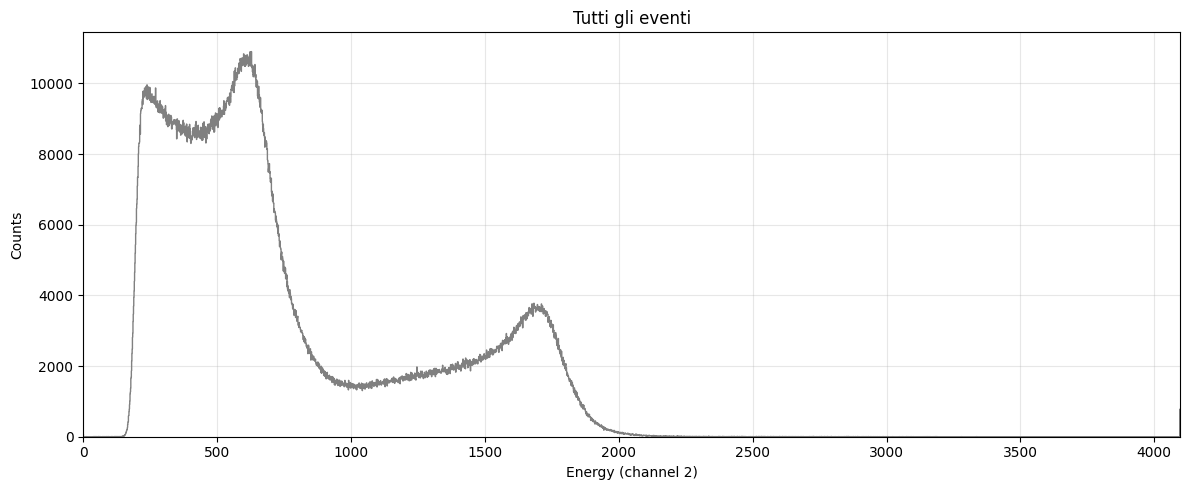

7519630


In [14]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5), sharey=True)

ax.hist(e, range=(0,4096), bins=4096, histtype='step', color='gray')
ax.set_title("Tutti gli eventi")
ax.set_xlabel("Energy (channel 2)")
ax.set_ylabel("Counts")
ax.set_xlim(0,4096)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(len(e))

#### Fit calibrazione D1

In [ ]:
hist_D1, c = load_hist("../data/calib_D1.root",0,draw=False, rangemin=0,rangemax=2100, nbins=2100, multitree=[4,5])
c = gaus_fit(hist_D1,550, 900)

In [ ]:
c = gaus_fit(hist_D1,1650, 1900)

A = 1624.4 ± 106.4   μ = 1719.21 ± 2.00     σ = 62.70 ± 2.52
Background lineare: q = 16068.56 ± 1080.45   sm = -8.21719 ± 0.56631


#### Fit calibrazione D2

In [ ]:
hist_D2, c = load_hist("../data/calib_D2.root",1,draw=False, rangemin=0,rangemax=1000, nbins=1000, multitree=[4,5])
c = gaus_fit(hist_D2,180, 270)

A = 10925.1 ± 326.3   μ = 211.42 ± 0.39     σ = 24.34 ± 0.50
Background lineare: q = 50019.20 ± 1260.28   sm = -155.06950 ± 4.41974


In [ ]:
hist_D2, c = load_hist("../data/calib_D2.root",1,draw=False, rangemin=0,rangemax=1000, nbins=1000, multitree=[4,5])
c = gaus_fit(hist_D2,645, 810, linear_bg=False)

A = 4997.4 ± 8.2   μ = 679.68 ± 0.34     σ = 71.77 ± 0.27


NON FUNZIONA, fit fatti su root

--- Calibrazione D1 ---
μ = a*E + b
a = 1.425497 ± 0.000835
b = -108.829 ± 0.849

--- Calibrazione D2 ---
μ = a*E + b
a = 0.609018 ± 0.001318
b = -102.398 ± 0.698


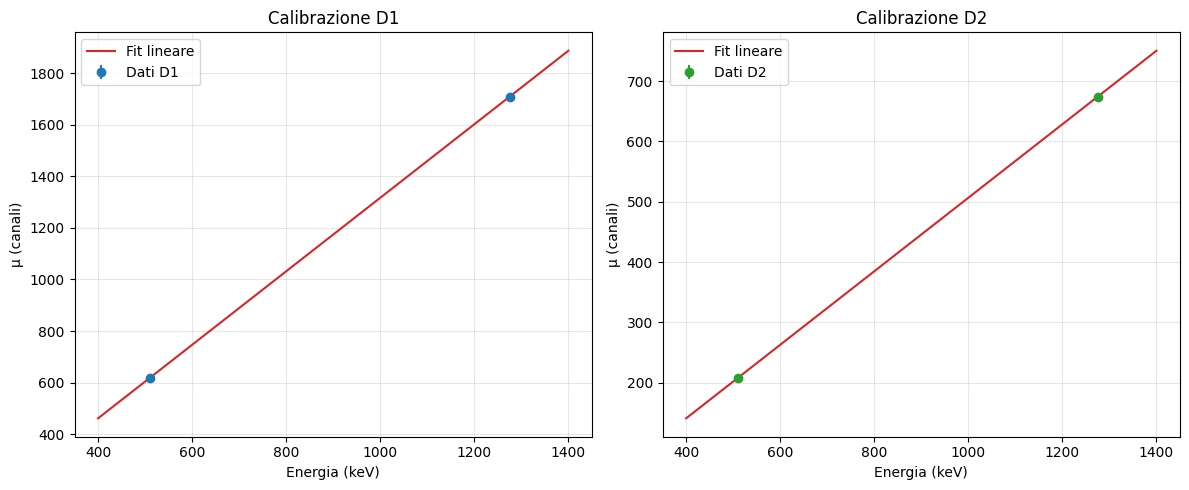

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


E_ref_D1 = np.array([511.0, 1275.0])  # keV
E_ref_D2 = np.array([511.0, 1275.0])


mu_D1 = np.array([619.60, 1708.68])
mu_err_D1 = np.array([0.48, 0.42])

mu_D2 = np.array([208.81, 674.10])
mu_err_D2 = np.array([0.12, 1.00])

def calib(E, a, b):
    return a * E + b

popt_D1, pcov_D1 = curve_fit(calib, E_ref_D1, mu_D1, sigma=mu_err_D1, absolute_sigma=True)
a1, b1 = popt_D1
a1_err, b1_err = np.sqrt(np.diag(pcov_D1))

print(f"--- Calibrazione D1 ---")
print(f"μ = a*E + b")
print(f"a = {a1:.6f} ± {a1_err:.6f}")
print(f"b = {b1:.3f} ± {b1_err:.3f}")

popt_D2, pcov_D2 = curve_fit(calib, E_ref_D2, mu_D2, sigma=mu_err_D2, absolute_sigma=True)
a2, b2 = popt_D2
a2_err, b2_err = np.sqrt(np.diag(pcov_D2))

print(f"\n--- Calibrazione D2 ---")
print(f"μ = a*E + b")
print(f"a = {a2:.6f} ± {a2_err:.6f}")
print(f"b = {b2:.3f} ± {b2_err:.3f}")


fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# D1
E_fit = np.linspace(400, 1400, 200)
ax[0].errorbar(E_ref_D1, mu_D1, yerr=mu_err_D1, fmt='o', color='tab:blue', label='Dati D1')
ax[0].plot(E_fit, calib(E_fit, *popt_D1), '-', color='tab:red', label='Fit lineare')
ax[0].set_title('Calibrazione D1')
ax[0].set_xlabel('Energia (keV)')
ax[0].set_ylabel('μ (canali)')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

# D2
E_fit = np.linspace(400, 1400, 200)
ax[1].errorbar(E_ref_D2, mu_D2, yerr=mu_err_D2, fmt='o', color='tab:green', label='Dati D2')
ax[1].plot(E_fit, calib(E_fit, *popt_D2), '-', color='tab:red', label='Fit lineare')
ax[1].set_title('Calibrazione D2')
ax[1].set_xlabel('Energia (keV)')
ax[1].set_ylabel('μ (canali)')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### TAC calibration

In [ ]:
import ROOT
import uproot
from ROOT import TFile, TTree, TH1D, TF1, TCanvas, gStyle
from lib.histo import *

ROOT.gErrorIgnoreLevel = ROOT.kError # Ignore info messages

In [ ]:
hist_0, c = load_hist("../data/calib_TAC_0ns.root",2,draw=False)
c = gaus_fit(hist_0,154, 215)

A = 845.1 ± 25.1   μ = 184.91 ± 0.31     σ = 15.10 ± 0.55
Background lineare: q = 195.06 ± 76.78   sm = 1.69650 ± 0.40715


In [ ]:
hist_2, c = load_hist("../data/calib_TAC_2ns.root",2,nbins=270,rangemin=150,rangemax=420,draw=False)
c = gaus_fit(hist_2, 250, 295)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/patrick/Desktop/Università/WS 25/Lab/Timing/notebooks/data/calib_TAC_2ns.root'

In [ ]:
hist_4, c = load_hist("../data/calib_TAC_4ns.root",2,nbins=200,rangemin=250,rangemax=450,draw=False)
c = gaus_fit(hist_4, 324, 381)

A = 899.6 ± 61.6   μ = 350.44 ± 0.51     σ = 17.29 ± 1.08


In [ ]:
hist_8,c = load_hist("../data/calib_TAC_8ns.root",2,nbins=200,rangemin=400,rangemax=600,draw=False)
c = gaus_fit(hist_8, 490, 543)

A = 827.6 ± 143.7   μ = 511.22 ± 1.27     σ = 18.72 ± 2.25


In [ ]:
hist_16,c = load_hist("../data/calib_TAC_16ns.root",2,nbins=350,rangemin=650,rangemax=1000,draw=False)
c = gaus_fit(hist_16, 810, 870)

A = 769.0 ± 27.7   μ = 838.88 ± 0.35     σ = 14.98 ± 0.65


In [ ]:
hist_24,c = load_hist("../data/calib_TAC_24ns.root",2,nbins=250,rangemin=1050,rangemax=1300,draw=False)
c = gaus_fit(hist_24, 1132, 1193)

A = 871.2 ± 36.7   μ = 1161.99 ± 0.37     σ = 16.52 ± 0.76


In [ ]:
hist_32,c = load_hist("../data/calib_TAC_32ns.root",2,nbins=150,rangemin=1400,rangemax=1550,draw=False)      
c = gaus_fit(hist_32, 1460, 1500)

A = 552.4 ± 54.6   μ = 1477.18 ± 0.63     σ = 10.46 ± 0.99


In [ ]:
hist_63,c = load_hist("../data/calib_TAC_63ns.root",2,nbins=181,rangemin=2650,rangemax=2830,draw=False)      
c = gaus_fit(hist_63, 2718, 2757)

A = 1030.8 ± 72.8   μ = 2741.06 ± 0.22     σ = 18.04 ± 0.95


In [ ]:
import numpy as np
from array import array

t_ref = np.array([0, 2, 4, 8, 16, 24, 32, 63], dtype=float)
mu = np.array([184.91, 272.17, 350.44, 511.22, 838.88, 1161.99, 1477.18, 2740.44], dtype=float)
mu_err = np.array([0.31, 0.39, 0.51, 1.27, 0.37, 0.16, 0.63, 0.24 ], dtype=float)

graph,c = linear_fit(t_ref, mu, mu_err)

Intercetta: 188.686 ± 0.171
Pendenza:   40.512 ± 0.005


## Cable Calibration

In [ ]:
hist_cable_21, c = load_hist("../data/cable_21cm.root",0,draw=True, nbins= 500, rangemin=0, rangemax=4000)
# c = gaus_fit(hist_cable_21,400, 700)